# ChinaT1 Pitch EDA: A-shares earn their return intraday and lose it overnight. Can an ETF holder harvest it?

**The constraint.** On the Shanghai and Shenzhen exchanges, shares and equity ETFs bought today cannot be sold until
the next trading day (T+1). A buyer at the open is locked in until tomorrow; a seller at the open can only be someone
who already held overnight. Studies of China's "overnight return puzzle" (e.g. Qiao & Dam 2020) find A-share
returns are positive intraday and negative overnight, the reverse of the US, and tie the pattern to T+1. The
regulation is the mechanism, and it has not changed.

**The trade that respects T+1 ("做T" rotation).** Hold one lot of the ETF. Each day buy a second lot in the **opening
call auction** (09:15–09:25) and sell **yesterday's** lot in the **closing call auction** (14:57–15:00). Overnight
exposure stays at one lot; the extra lot earns the open→close return every day. Both trades are in call auctions
(no bid-ask spread). Equity ETFs pay no stamp duty; ETF commissions are about 0.5bp per side, so about 1.5bp a day
all-in (3bp shown as a stress).

**Questions.**
1. Is the intraday premium in the indices themselves, in both eras?
2. Which liquid ETFs capture it, and is it ETF-specific (opening discounts) or market-wide?
3. Net of costs, does it clear in-sample (≤2018) and out-of-sample (2019–) with t ≥ 2? By year?
4. What does the full position earn, including the overnight lot?

**Data.** Sina daily OHLC via AkShare for ETFs and indices (`collect_sina.py`; open = opening auction print, close =
closing auction). Cross-checked against Yahoo (`collect.py`): same means. Intraday (open→close of the same day)
returns need no split or dividend adjustment.

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
SPLIT = pd.Timestamp("2019-01-01")
e = pd.read_csv("data/sina_etfs.csv", parse_dates=["date"])
ix = pd.read_csv("data/sina_indices.csv", parse_dates=["date"])
def legs(g):
    g = g.set_index("date").sort_index()
    idr = np.log(g.close / g.open) * 1e4
    on = np.log(g.open / g.close.shift(1)) * 1e4
    ok = (idr.abs() < 1500) & (on.abs() < 1500)        # drop split days / bad prints (rare)
    return pd.DataFrame({"intraday": idr, "overnight": on, "amount": g.get("amount")})[ok]
ETF = {c: legs(g) for c, g in e.groupby("code")}
IDX = {c: legs(g) for c, g in ix.groupby("index")}
NAMES = dict(e[["code", "name"]].drop_duplicates().values)
print({k: (v.index.min().date(), len(v)) for k, v in ETF.items()})

{'sh510050': (datetime.date(2005, 2, 24), 5258), 'sh510210': (datetime.date(2011, 3, 28), 3726), 'sh510300': (datetime.date(2012, 5, 29), 3493), 'sh510330': (datetime.date(2013, 1, 17), 3335), 'sh510500': (datetime.date(2013, 3, 18), 3294), 'sh512100': (datetime.date(2016, 11, 7), 2411), 'sh512500': (datetime.date(2015, 8, 5), 2717), 'sh588000': (datetime.date(2020, 11, 17), 1431), 'sz159845': (datetime.date(2021, 4, 1), 1339), 'sz159915': (datetime.date(2011, 12, 12), 3600), 'sz159919': (datetime.date(2012, 5, 29), 3490), 'sz159922': (datetime.date(2013, 3, 18), 3297)}


## 2. The market-wide pattern: indices
**What this does.** Mean open→close and close→open log returns (bp/day) of the main indices, ≤2018 vs 2019–, with
t-stats. Index opens are partly stale (a stock that has not traded yet enters the open at yesterday's close), which
pulls the measured index open toward the previous close and *understates* the intraday leg.

In [2]:
INAME = {"sh000001": "SSE Composite", "sh000300": "CSI 300", "sh000905": "CSI 500", "sh000852": "CSI 1000", "sz399006": "ChiNext"}
rows = []
for c, d in IDX.items():
    for per, m in [("≤2018", d.index < SPLIT), ("2019–", d.index >= SPLIT)]:
        x = d[m]
        if len(x) < 200: continue
        rows.append({"index": INAME[c], "era": per, "days": len(x), "intraday bp": x.intraday.mean(),
                     "t intraday": x.intraday.mean() / x.intraday.std() * np.sqrt(len(x)), "overnight bp": x.overnight.mean(),
                     "t overnight": x.overnight.mean() / x.overnight.std() * np.sqrt(len(x))})
print(pd.DataFrame(rows).round(2).to_string(index=False))

        index   era  days  intraday bp  t intraday  overnight bp  t overnight
SSE Composite ≤2018  6845         2.40        1.14         -0.77        -0.66
SSE Composite 2019–  1886         7.47        3.54         -5.37        -4.13
      CSI 300 ≤2018  4122         9.28        4.06         -7.28        -5.28
      CSI 300 2019–  1886         5.41        2.28         -3.68        -2.44
     CSI 1000 ≤2018  1028        12.92        2.23        -15.96        -6.20
     CSI 1000 2019–  1886         7.72        2.36         -5.55        -3.43
      CSI 500 ≤2018  3401        14.52        4.48        -10.28        -8.24
      CSI 500 2019–  1886         6.76        2.31         -4.19        -2.68
      ChiNext ≤2018  2087        13.32        3.19        -12.12        -7.96
      ChiNext 2019–  1885         4.39        1.17         -0.99        -0.51


**Interpretation.** The CSI 300, CSI 500 and CSI 1000 earn their return intraday and give part back overnight in
**both** eras: intraday t 4.1 / 4.5 / 2.2 up to 2018 and 2.3 / 2.3 / 2.4 since 2019, with significantly negative
overnights. The SSE Composite's long history (back to 1990) is weak before 2019 (t 1.1) but strong since (t 3.5).
ChiNext is strong before 2019 (t 3.2) and weaker since (t 1.2, though its ETF still clears, see §3). The premium is
market-wide, not an ETF quirk, and a long-standing regulation keeps it in place.

## 3. The liquid ETFs: intraday leg net of costs
**What this does.** For each ETF: the intraday return of the extra lot net of 1.5bp and 3bp per day, by era (and
≤2018 without the 2015 bubble/crash), with t-stats and annualised Sharpe (244 trading days), the gap to its index's
intraday return, and median daily turnover (capacity).

In [3]:
MAP = {"sh510500": "sh000905", "sz159922": "sh000905", "sh512500": "sh000905", "sh510300": "sh000300", "sz159919": "sh000300",
       "sh510330": "sh000300", "sz159915": "sz399006", "sh512100": "sh000852", "sz159845": "sh000852", "sh510210": "sh000001"}
rows = []
for c, d in ETF.items():
    for cost in [1.5, 3.0]:
        for per, m in [("≤2018", d.index < SPLIT), ("≤2018 ex-2015", (d.index < SPLIT) & (d.index.year != 2015)), ("2019–", d.index >= SPLIT)]:
            x = d.intraday[m] - cost
            if len(x) < 250: continue
            gap = (d.intraday - IDX[MAP[c]].intraday.reindex(d.index))[m].dropna() if c in MAP else pd.Series(dtype=float)
            rows.append({"ETF": f"{c} {NAMES[c]}", "cost": cost, "era": per, "net bp/day": x.mean(), "t": x.mean() / x.std() * np.sqrt(len(x)),
                         "Sharpe": x.mean() / x.std() * np.sqrt(244), "ETF−index bp": gap.mean() if len(gap) else np.nan,
                         "turnover CNY m": d.amount[m].median() / 1e6})
T = pd.DataFrame(rows)
print(T[T.cost == 1.5].round(2).to_string(index=False))
print("\n3bp stress (2019– and ≤2018):")
print(T[(T.cost == 3.0) & (T.era != "≤2018 ex-2015")].round(2).to_string(index=False))

                              ETF  cost           era  net bp/day     t  Sharpe  ETF−index bp  turnover CNY m
                   sh510050 SSE50   1.5         ≤2018        9.37  3.37    0.91           NaN          654.24
                   sh510050 SSE50   1.5 ≤2018 ex-2015        9.87  3.56    0.99           NaN          617.82
                   sh510050 SSE50   1.5         2019–        2.89  1.22    0.44           NaN         1844.68
sh510210 SSE Composite (Fullgoal)   1.5         ≤2018       32.33  7.04    2.56         22.18            0.07
sh510210 SSE Composite (Fullgoal)   1.5 ≤2018 ex-2015       32.98  7.37    2.88         25.06            0.06
sh510210 SSE Composite (Fullgoal)   1.5         2019–       10.91  4.92    1.77          4.95           78.34
         sh510300 CSI300 (Huatai)   1.5         ≤2018        5.20  1.48    0.58         -3.02          701.31
         sh510300 CSI300 (Huatai)   1.5 ≤2018 ex-2015        4.04  1.33    0.56         -2.86          661.63
         s

**Interpretation.**
- **The two that clear the bar are the liquid mid/small-cap ETFs:**
  - **ChiNext ETF 159915:** +17.9bp/day net in ≤2018 (t 3.5; t 2.6 without 2015) and +8.8bp/day in 2019– (t 2.3), net of 1.5bp.
  - **CSI 500 ETF 510500:** +13.8 (t 2.9; t 1.9 without 2015) and +7.3 (t 2.5).
  - Annual Sharpe of the intraday lot is 0.8–1.3.
- **Large-cap ETFs do not clear both eras:** CSI 300 ETFs earn about +3–6bp net (t 1.2–1.7). The SSE 50 ETF cleared
  in-sample (t 3.4) but not since 2019 (t 1.2). In China, T+1 bites harder in retail-heavy mid and small caps.
- **Newer mid/small-cap ETFs agree since 2019:** CSI 1000 (512100 t 3.6; 159845 t 2.3) and CSI 500 (512500 t 2.0). Their
  pre-2019 rows are from years when they were nearly untraded (turnover about CNY 1m/day). The thin SSE Composite ETF 510210
  shows huge numbers but trades almost nothing, so its prints are not executable at size.
- **The ETFs beat their own index intraday** (ChiNext +5–6bp/day, CSI 500 +2–3bp). That is the stale-open bias in index
  opens; the ETFs' opening auction is a real, tradable price. 159922 (the other CSI 500 ETF) trails its index; it was
  nearly untraded before 2019, so its auction prints are noisy.
- **Cost sensitivity is the main risk:** at 3bp/day the out-of-sample t falls to 1.9–2.0.

## 4. By year, and the whole position
**What this does.** Net intraday-lot P&L by year for the two passing ETFs, and cumulative P&L of (a) the extra lot alone,
(b) buy-and-hold one lot, (c) the full rotation position (two lots intraday, one overnight).

sz159915 net intraday-lot bp/day by year: {2011: -16.8, 2012: 11.6, 2013: 48.4, 2014: 18.0, 2015: 54.5, 2016: -2.7, 2017: 2.1, 2018: -3.9, 2019: 14.2, 2020: 24.2, 2021: 12.9, 2022: -1.0, 2023: -11.1, 2024: 9.7, 2025: 19.5, 2026: -0.1}
sh510500 net intraday-lot bp/day by year: {2013: 31.2, 2014: 15.3, 2015: 44.0, 2016: 2.2, 2017: 4.0, 2018: -8.5, 2019: 11.0, 2020: 15.1, 2021: 13.1, 2022: -1.6, 2023: -5.3, 2024: 1.6, 2025: 18.5, 2026: 4.5}


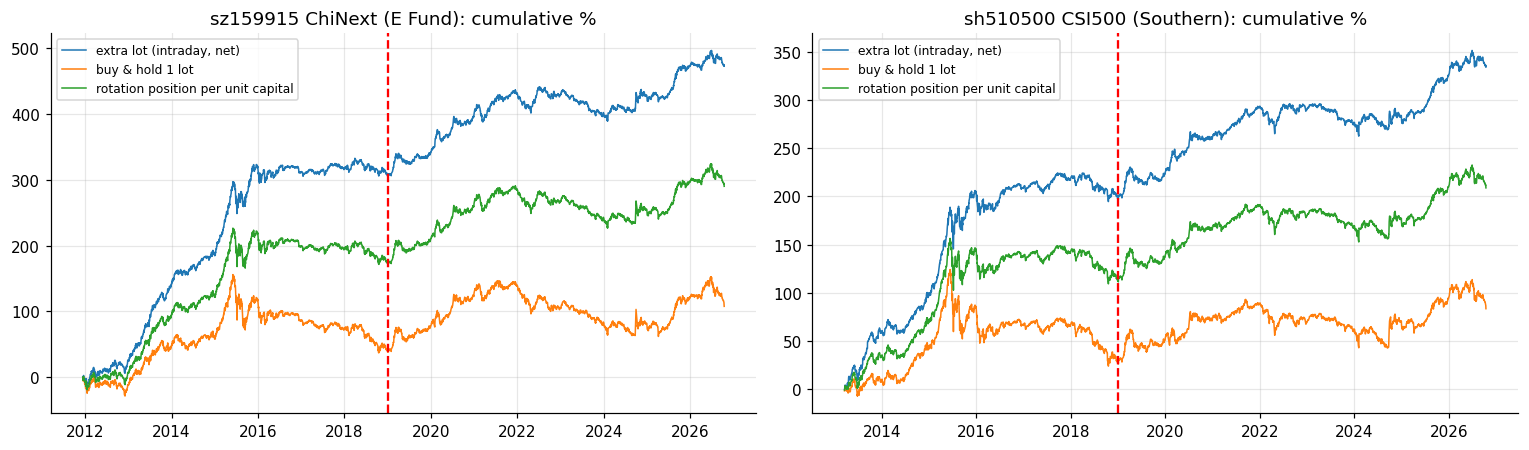

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, c in zip(ax, ["sz159915", "sh510500"]):
    d = ETF[c]; lot = d.intraday - 1.5
    bh = d.intraday + d.overnight
    full = 2 * d.intraday + d.overnight - 1.5
    for s, lab in [(lot, "extra lot (intraday, net)"), (bh, "buy & hold 1 lot"), (full / 2, "rotation position per unit capital")]:
        a.plot(s.index, s.cumsum() / 100, label=lab, lw=1)
    a.axvline(SPLIT, c="r", ls="--"); a.set_title(f"{c} {NAMES[c]}: cumulative %"); a.legend(fontsize=8)
    print(c, "net intraday-lot bp/day by year:", lot.groupby(lot.index.year).mean().round(1).to_dict())
plt.tight_layout(); plt.show()

**Interpretation.** The extra lot is positive in most years (ChiNext: negative in 2011, 2016, 2018, 2022, 2023;
CSI 500: negative in 2018, 2022, 2023), largest in high-volume retail years (2013–15, 2019–21, 2025). Buy-and-hold
earns almost nothing, because the negative overnights eat the intraday gains. The rotation position earns roughly
the intraday lot plus a smaller buy-and-hold component. The overnight lot can be hedged with CSI 500 index futures (IC)
where accessible.

## 5. Takeaways

| question | answer |
|---|---|
| Is the premium market-wide? | Yes. CSI 300 / 500 / 1000 positive intraday, negative overnight in both eras (intraday t 2.2–4.5). |
| Mechanism | China's T+1 rule (unchanged for decades). Open buyers are locked in overnight, so opening auctions clear low. |
| Tradable (net 1.5bp/day) | ChiNext ETF: t 3.5 (≤2018) / 2.3 (2019–). CSI 500 ETF: t 2.9 / 2.5. Sharpe of the intraday lot 0.8–1.3. |
| Weak spots | Cost-sensitive (t 1.9–2.0 at 3bp). CSI 500 in-sample t 1.9 without 2015. Large-cap ETFs do not clear. Several negative years. |

**Verdict: promising and tradable for an investor with A-share ETF access** (Stock Connect northbound lists both
ETFs). The anomaly is market-wide, regulatory in origin, present in both eras and both data sources, and harvested with
auction-only execution that respects T+1.

**Before pitching it as a strategy:** confirm commission levels for the intended broker / Connect route (the result needs
≤ about 2bp/day all-in); test with exchange auction prices from a second vendor (Wind / Tushare); and design the overnight
hedge (IC futures) for a market-neutral version.